# Auswertung der Ergebnisse: Studie Teil 2

Vergleich von 3 Prompting-Strategien anhand von 2 Modellen. Ziel: Inhaltliche Verbesserung.

Modelle:
* NuExtract3-4B
* Qwen2.5-7B-instruct

In [1]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

df = pd.read_csv('ergebnisse_studie_teil2_prompting_strategien.csv', sep=';', decimal=',')

In [2]:
df.head(10)

,Run_ID,Modell,Artikel_ID,Strategie,Input_Token,Output_Token,Laufzeit_in_s,JSON_parsbar,TP,FN,FP,Document_Perfect_Match,Artikelnummer?
0,1,Qwen2.5-7B-instruct,20323-000,Few-Shot-2,5697,270,38.984,1,14,1,8,0,0
1,2,Qwen2.5-7B-instruct,20323-000,Few-Shot-4,8746,189,68.066,1,14,1,1,0,0
2,3,Qwen2.5-7B-instruct,20323-000,Zero-Shot,2548,189,9.949,1,14,1,1,0,0
3,4,Qwen2.5-7B-instruct,40402-405,Few-Shot-2,4757,135,9.664,1,11,1,0,0,0
4,5,Qwen2.5-7B-instruct,40402-405,Few-Shot-4,7806,144,52.943,1,12,0,0,1,1
5,6,Qwen2.5-7B-instruct,40402-405,Zero-Shot,1608,135,4.475,1,11,1,0,0,0
6,7,Qwen2.5-7B-instruct,40135-014,Few-Shot-2,4735,134,26.285,1,6,1,5,0,0
7,8,Qwen2.5-7B-instruct,40135-014,Few-Shot-4,7784,144,52.404,1,7,0,5,0,1
8,9,Qwen2.5-7B-instruct,40135-014,Zero-Shot,1586,76,3.469,1,6,1,0,0,0
9,10,Qwen2.5-7B-instruct,30160-875,Few-Shot-2,10385,270,98.823,1,9,1,13,0,0


In [3]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 60 entries, 0 to 59
Data columns (total 13 columns):
 #   Column                  Non-Null Count  Dtype  
---  ------                  --------------  -----  
 0   Run_ID                  60 non-null     int64  
 1   Modell                  60 non-null     object 
 2   Artikel_ID              60 non-null     object 
 3   Strategie               60 non-null     object 
 4   Input_Token             60 non-null     int64  
 5   Output_Token            60 non-null     int64  
 6   Laufzeit_in_s           60 non-null     float64
 7   JSON_parsbar            60 non-null     int64  
 8   TP                      60 non-null     int64  
 9   FN                      60 non-null     int64  
 10  FP                      60 non-null     int64  
 11  Document_Perfect_Match  60 non-null     int64  
 12  Artikelnummer?          60 non-null     int64  
dtypes: float64(1), int64(9), object(3)
memory usage: 6.2+ KB


## Precision & Recall

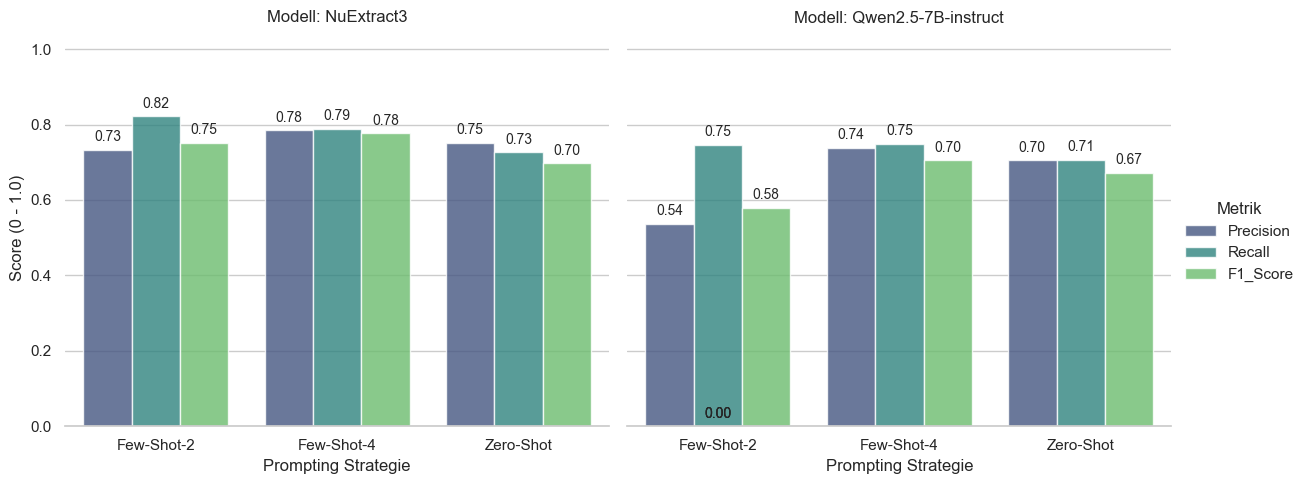

In [4]:
# 2. Metriken pro Zeile berechnen
# Division durch 0 abfangen (falls TP+FP oder TP+FN mal 0 sein sollten)
df['Precision'] = (df['TP'] / (df['TP'] + df['FP'])).fillna(0)
df['Recall'] = (df['TP'] / (df['TP'] + df['FN'])).fillna(0)
df['F1_Score'] = (2 * (df['Precision'] * df['Recall']) / (df['Precision'] + df['Recall'])).fillna(0)

# 3. Durchschnitt (Macro-Average) pro Modell und Strategie berechnen
grouped = df.groupby(['Modell', 'Strategie'])[['Precision', 'Recall', 'F1_Score']].mean().reset_index()

# 4. Datenstruktur für Seaborn anpassen (Melting)
melted = grouped.melt(
    id_vars=['Modell', 'Strategie'], 
    value_vars=['Precision', 'Recall', 'F1_Score'], 
    var_name='Metrik', 
    value_name='Wert'
)

# 5. Visualisierung erstellen (Ein Plot pro Modell)
sns.set_theme(style="whitegrid")
g = sns.catplot(
    data=melted, 
    kind="bar",
    x="Strategie", 
    y="Wert", 
    hue="Metrik", 
    col="Modell",
    palette="viridis", 
    alpha=.8, 
    height=5, 
    aspect=1.2
)

# Design-Anpassungen
g.despine(left=True)
g.set_axis_labels("Prompting Strategie", "Score (0 - 1.0)")
g.set_titles("Modell: {col_name}")
g.set(ylim=(0, 1.05))

# Werte direkt über die Balken schreiben
for ax in g.axes.flat:
    for p in ax.patches:
        ax.annotate(format(p.get_height(), '.2f'), 
                    (p.get_x() + p.get_width() / 2., p.get_height()), 
                    ha='center', va='center', 
                    xytext=(0, 9), 
                    textcoords='offset points',
                    fontsize=10)


# Als PDF speichern
plt.savefig("Prompting_Strategien.pdf", format="pdf", bbox_inches="tight")                   

plt.show()

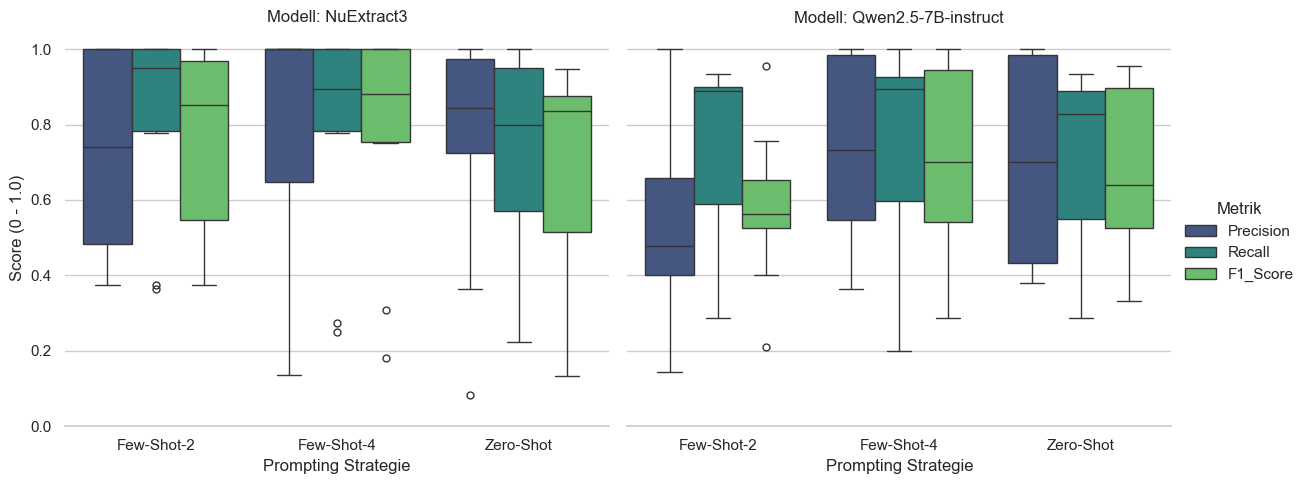

In [5]:
import seaborn as sns
import matplotlib.pyplot as plt

# 1 & 2. Metriken berechnen (wie bisher)
df['Precision'] = (df['TP'] / (df['TP'] + df['FP'])).fillna(0)
df['Recall'] = (df['TP'] / (df['TP'] + df['FN'])).fillna(0)
df['F1_Score'] = (2 * (df['Precision'] * df['Recall']) / (df['Precision'] + df['Recall'])).fillna(0)

model_order = ['NuExtract3', 'Qwen2.5-7B-instruct']

# 3. WICHTIG: KEIN Groupby.mean() durchführen! 
# Wir schmelzen direkt das rohe DataFrame, damit Seaborn alle Werte kennt.
melted = df.melt(
    id_vars=['Modell', 'Strategie'], 
    value_vars=['Precision', 'Recall', 'F1_Score'], 
    var_name='Metrik', 
    value_name='Wert'
 )

# 4. Boxplot erstellen (Ein Plot pro Modell)
sns.set_theme(style="whitegrid")
g = sns.catplot(
    data=melted, 
    kind="box",      # <-- Hier auf 'box' umgestellt
    x="Strategie", 
    y="Wert", 
    hue="Metrik", 
    col="Modell",
    col_order=model_order,
    palette="viridis", 
    height=5, 
    aspect=1.2
)

# Design-Anpassungen
g.despine(left=True)
g.set_axis_labels("Prompting Strategie", "Score (0 - 1.0)")
g.set_titles("Modell: {col_name}")
g.set(ylim=(0, 1.05))

plt.show()

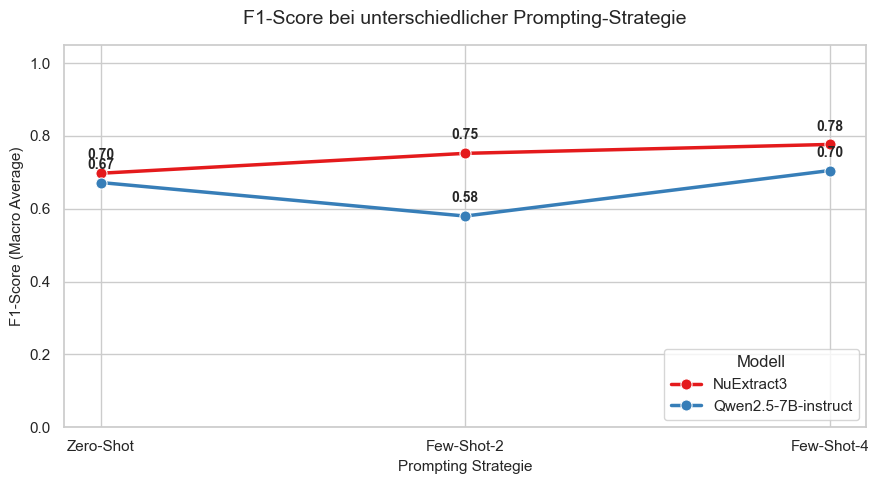

In [6]:
# 2. F1-Score berechnen
df['Precision'] = (df['TP'] / (df['TP'] + df['FP'])).fillna(0)
df['Recall'] = (df['TP'] / (df['TP'] + df['FN'])).fillna(0)
df['F1_Score'] = (2 * (df['Precision'] * df['Recall']) / (df['Precision'] + df['Recall'])).fillna(0)

# 3. Durchschnitt (Macro-Average) für F1-Score pro Modell und Strategie berechnen
grouped = df.groupby(['Modell', 'Strategie'])['F1_Score'].mean().reset_index()

# 4. WICHTIG: Die Reihenfolge der Strategien auf der X-Achse festlegen
strategy_order = ['Zero-Shot', 'Few-Shot-2', 'Few-Shot-4']
grouped['Strategie'] = pd.Categorical(grouped['Strategie'], categories=strategy_order, ordered=True)
grouped = grouped.sort_values(['Modell', 'Strategie'])

# 5. Liniendiagramm (Kurve) erstellen
plt.figure(figsize=(9, 5))
sns.set_theme(style="whitegrid")

# Das lineplot zeichnet die Kurven, 'marker="o"' setzt sichtbare Punkte auf die Werte
g = sns.lineplot(
    data=grouped, 
    x='Strategie', 
    y='F1_Score', 
    hue='Modell', 
    marker='o', 
    markersize=8, 
    linewidth=2.5,
    palette='Set1'
)

# Design-Anpassungen
plt.title('F1-Score bei unterschiedlicher Prompting-Strategie', fontsize=14, pad=15)
plt.ylabel('F1-Score (Macro Average)', fontsize=11)
plt.xlabel('Prompting Strategie', fontsize=11)
plt.ylim(0, 1.05)
plt.legend(title='Modell', loc='lower right')

# Werte als Text direkt an die Punkte schreiben
for line in g.lines:
    for x_value, y_value in zip(line.get_xdata(), line.get_ydata()):
        # Vermeidet, dass NaN-Werte beschriftet werden
        if pd.notna(y_value):
            plt.annotate(
                f'{y_value:.2f}', 
                (x_value, y_value),
                textcoords="offset points", 
                xytext=(0, 10), 
                ha='center',
                fontsize=10,
                fontweight='bold'
            )


# Als PDF speichern
plt.savefig("f1_score.pdf", format="pdf", bbox_inches="tight")

plt.tight_layout()
plt.show()

**Präzision (Precision):** Wie sehr kannst du den Antworten des Modells vertrauen? Sie misst den Anteil der *korrekten* Extraktionen an *allen* Werten, die das Modell ausgegeben hat. Eine hohe Präzision bedeutet, dass das Modell kaum Dinge erfindet oder falsch zuordnet (wenig False Positives/Halluzinationen).

**Vollständigkeit (Recall):** Wie viel geht dir verloren? Der Recall misst den Anteil der korrekt gefundenen Werte an allen Informationen, die *tatsächlich im Dokument standen*. Ein hoher Recall bedeutet, dass das Modell kaum relevante Daten übersieht oder weglässt (wenig False Negatives).

**F1-Score:** Die goldene Mitte. Modelle neigen dazu, einen Trade-off einzugehen: Sie sind entweder extrem vorsichtig (hohe Präzision, schlechter Recall) oder raten wild drauflos, um ja nichts zu verpassen (hoher Recall, miese Präzision). Der F1-Score bildet das harmonische Mittel aus beiden Werten und gilt als die wichtigste Einzelmetrik, um die echte Gesamtleistung zu bewerten.

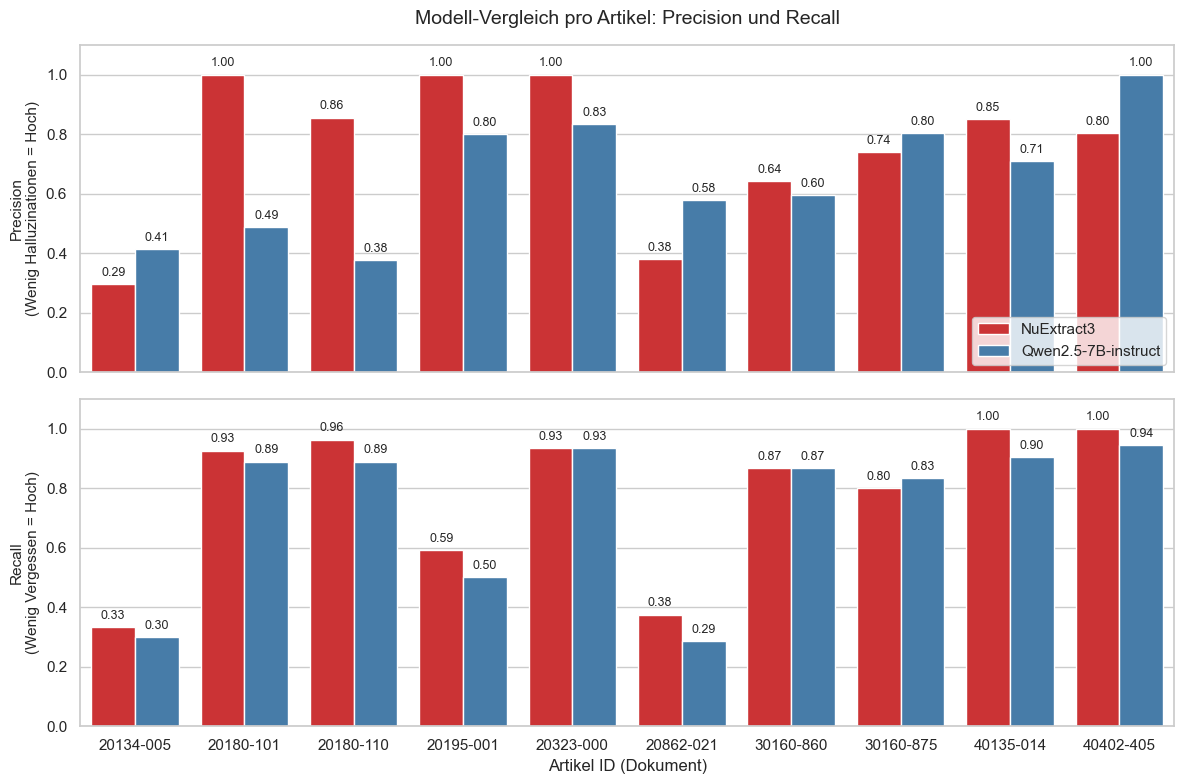

In [7]:
# 2. Precision und Recall berechnen
df['Precision'] = (df['TP'] / (df['TP'] + df['FP'])).fillna(0)
df['Recall'] = (df['TP'] / (df['TP'] + df['FN'])).fillna(0)

# 3. Aggregieren: Durchschnitt pro Artikel und Modell
grouped = df.groupby(['Artikel_ID', 'Modell'])[['Precision', 'Recall']].mean().reset_index()

# 4. Schaubild erstellen: 2 Plots übereinander (Subplots)
fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(12, 8), sharex=True)
sns.set_theme(style="whitegrid")

# Oberes Diagramm: Precision
sns.barplot(
    data=grouped, 
    x='Artikel_ID', 
    y='Precision', 
    hue='Modell', 
    ax=ax1, 
    palette='Set1'
)
ax1.set_title('Modell-Vergleich pro Artikel: Precision und Recall', fontsize=14, pad=15)
ax1.set_ylabel('Precision\n(Wenig Halluzinationen = Hoch)', fontsize=11)
ax1.set_ylim(0, 1.1)
ax1.legend(loc='lower right')

# Unteres Diagramm: Recall
sns.barplot(
    data=grouped, 
    x='Artikel_ID', 
    y='Recall', 
    hue='Modell', 
    ax=ax2, 
    palette='Set1'
)
ax2.set_ylabel('Recall\n(Wenig Vergessen = Hoch)', fontsize=11)
ax2.set_xlabel('Artikel ID (Dokument)', fontsize=12)
ax2.set_ylim(0, 1.1)

# Legende im unteren Diagramm ausblenden (da sie schon oben ist)
ax2.get_legend().remove()

# Werte über die Balken schreiben
for ax in [ax1, ax2]:
    for p in ax.patches:
        height = p.get_height()
        if pd.notna(height) and height > 0:
            ax.annotate(f'{height:.2f}', 
                        (p.get_x() + p.get_width() / 2., height), 
                        ha='center', va='center', 
                        xytext=(0, 8), 
                        textcoords='offset points',
                        fontsize=9)

plt.tight_layout()
plt.show()

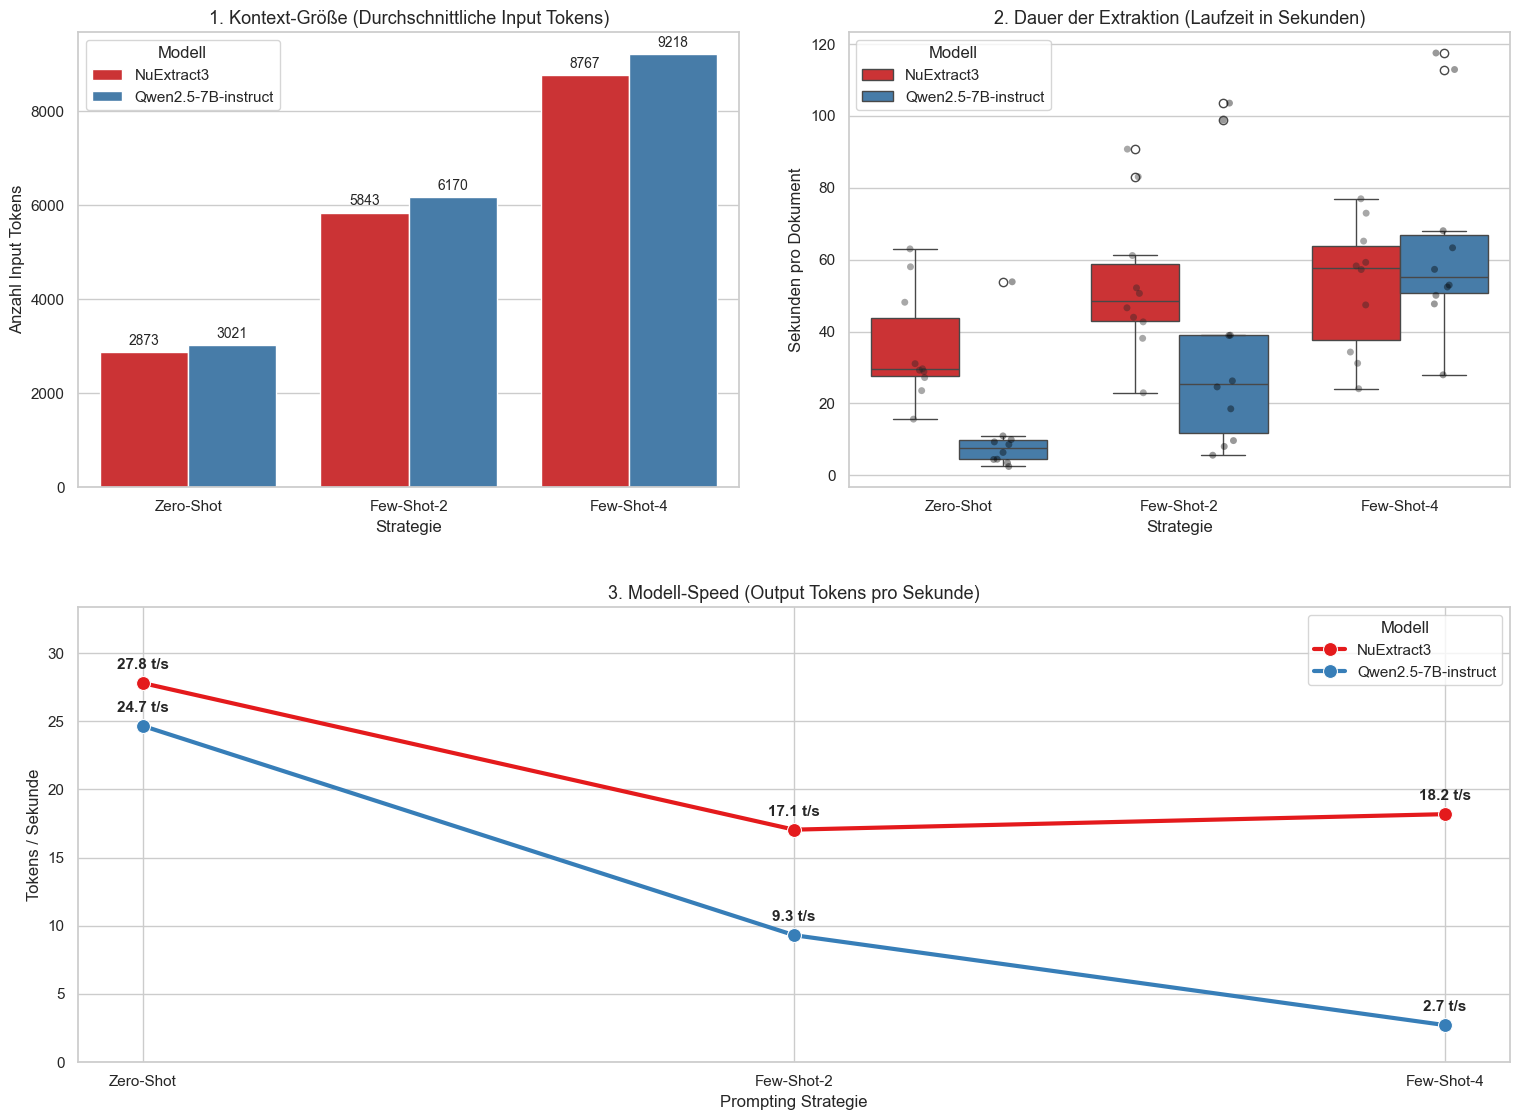

In [8]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np


df['Laufzeit_in_s'] = df['Laufzeit_in_s'].astype(str).str.replace(',', '.').astype(float)

# Berechne Token-Geschwindigkeit (Generierungsgeschwindigkeit)
# Wichtig für LLMs: Wie viele Output-Tokens pro Sekunde schafft das Modell?
df['Output_Tokens_per_Sec'] = df['Output_Token'] / df['Laufzeit_in_s']

# Sortierung der Strategien festlegen
strategy_order = ['Zero-Shot', 'Few-Shot-2', 'Few-Shot-4']
df['Strategie'] = pd.Categorical(df['Strategie'], categories=strategy_order, ordered=True)
model_order = ['NuExtract3', 'Qwen2.5-7B-instruct']

# Plot-Umgebung aufbauen (3 Schaubilder)
fig = plt.figure(figsize=(16, 12))
sns.set_theme(style="whitegrid")

# --- PLOT 1: Die Token-Kosten (Input Tokens) ---
ax1 = plt.subplot(2, 2, 1)
sns.barplot(data=df, x='Strategie', y='Input_Token', hue='Modell', hue_order=model_order, palette='Set1', ax=ax1, errorbar=None)
ax1.set_title('1. Kontext-Größe (Durchschnittliche Input Tokens)', fontsize=13)
ax1.set_ylabel('Anzahl Input Tokens')
# Werte auf die Balken schreiben
for p in ax1.patches:
    height = p.get_height()
    if pd.notna(height) and height > 0:
        ax1.annotate(f'{int(height)}', (p.get_x() + p.get_width() / 2., height), 
                     ha='center', va='center', xytext=(0, 8), textcoords='offset points', fontsize=10)

# --- PLOT 2: Laufzeit-Entwicklung ---
ax2 = plt.subplot(2, 2, 2)
sns.boxplot(data=df, x='Strategie', y='Laufzeit_in_s', hue='Modell', hue_order=model_order, palette='Set1', ax=ax2)
sns.stripplot(data=df, x='Strategie', y='Laufzeit_in_s', hue='Modell', hue_order=model_order, palette='dark:black', ax=ax2, dodge=True, alpha=0.4, legend=False)
ax2.set_title('2. Dauer der Extraktion (Laufzeit in Sekunden)', fontsize=13)
ax2.set_ylabel('Sekunden pro Dokument')

# --- PLOT 3: Generierungs-Geschwindigkeit (Throughput) ---
ax3 = plt.subplot(2, 1, 2)
# Hier nutzen wir ein Liniendiagramm, um zu zeigen, ob längerer Kontext das Modell ausbremst
throughput = df.groupby(['Modell', 'Strategie'], observed=True)['Output_Tokens_per_Sec'].mean().reset_index()
sns.lineplot(data=throughput, x='Strategie', y='Output_Tokens_per_Sec', hue='Modell', 
             marker='o', markersize=10, linewidth=3, palette='Set1', ax=ax3)

ax3.set_title('3. Modell-Speed (Output Tokens pro Sekunde)', fontsize=13)
ax3.set_ylabel('Tokens / Sekunde')
ax3.set_xlabel('Prompting Strategie')
ax3.set_ylim(0, max(throughput['Output_Tokens_per_Sec']) * 1.2)

# Annotations für die Punkte
for line in ax3.lines:
    for x_value, y_value in zip(line.get_xdata(), line.get_ydata()):
        if pd.notna(y_value):
            ax3.annotate(f'{y_value:.1f} t/s', (x_value, y_value), textcoords="offset points", xytext=(0, 10), ha='center', fontsize=11, fontweight='bold')

plt.tight_layout(pad=3.0)
plt.show()